Version E — LSTM variant `units256`: lstm_units raised from 128 (baseline) to 256, all other hyperparameters unchanged (`embedding_dim=128, dropout=0.3, learning_rate=1e-3`). Bigger recurrent layer capacity.

In [1]:
%pip install tensorflow
%pip install scikit-learn pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import json
import pickle
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import callbacks, layers, models
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

SEED = 42
tf.keras.utils.set_random_seed(SEED)

TAG = "units256"
EMBEDDING_DIM = 128
LSTM_UNITS = 256
DROPOUT = 0.3
LEARNING_RATE = 0.001
RECURRENT_DROPOUT = 0.0  # nonzero disables the cuDNN LSTM kernel - moot on this CPU-only machine, kept for consistency/portability

print("GPUs visible to TensorFlow:", tf.config.list_physical_devices("GPU"))
print(f"Variant {TAG}: embedding_dim={EMBEDDING_DIM}, lstm_units={LSTM_UNITS}, dropout={DROPOUT}, learning_rate={LEARNING_RATE}")

GPUs visible to TensorFlow: []
Variant units256: embedding_dim=128, lstm_units=256, dropout=0.3, learning_rate=0.001


In [3]:
SPLITS_DIR = Path("../../data/splits")
ARTIFACTS_DIR = Path("../../data/artifacts")
RESULTS_DIR = Path("../../../results/lstm")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR = Path("../../weights/lstm_variants") / TAG
MODELS_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(SPLITS_DIR / "train.csv")
val_df = pd.read_csv(SPLITS_DIR / "val.csv")
test_df = pd.read_csv(SPLITS_DIR / "test.csv")

with open(ARTIFACTS_DIR / "label_encoder.pkl", "rb") as f:
    label_encoder = pickle.load(f)

LABEL_ORDER = list(label_encoder.classes_)
NUM_CLASSES = len(LABEL_ORDER)

y_train = label_encoder.transform(train_df["category"])
y_val = label_encoder.transform(val_df["category"])
y_test = label_encoder.transform(test_df["category"])

print("Train/val/test sizes:", len(train_df), len(val_df), len(test_df))
print("Classes:", LABEL_ORDER)

Train/val/test sizes: 224828 48178 48178
Classes: ['Business', 'Entertainment', 'Health', 'Politics', 'Science', 'Sports', 'Technology', 'World']


In [4]:
VOCAB_SIZE = 20000

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df["text"])

train_token_counts = train_df["text"].fillna("").astype(str).str.split().str.len()
p95 = int(np.percentile(train_token_counts, 95))
MAX_LEN = int(np.clip(p95, 20, 200))
print(f"95th percentile train token count: {p95}, MAX_LEN clamped to: {MAX_LEN}")


def to_padded(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAX_LEN, padding="post", truncating="post")


X_train = to_padded(train_df["text"])
X_val = to_padded(val_df["text"])
X_test = to_padded(test_df["text"])

print("X_train shape:", X_train.shape)

95th percentile train token count: 561, MAX_LEN clamped to: 200


X_train shape: (224828, 200)


In [5]:
model = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, mask_zero=True),
    layers.Bidirectional(
        layers.LSTM(LSTM_UNITS, dropout=DROPOUT, recurrent_dropout=RECURRENT_DROPOUT, return_sequences=False)
    ),
    layers.Dropout(DROPOUT),
    layers.Dense(64, activation="relu"),
    layers.Dropout(DROPOUT),
    layers.Dense(NUM_CLASSES, activation="softmax"),
])
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 512)            │       788,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,381,832 (12.90 MB)

 Trainable params: 3,381,832 (12.90 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
BATCH_SIZE = 64
EPOCHS = 15

callback_list = [
    callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    callbacks.ModelCheckpoint(
        filepath=str(MODELS_DIR / "lstm_model.keras"),
        monitor="val_loss",
        save_best_only=True,
    ),
]

start_time = time.time()
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callback_list,
    verbose=2,
)
train_time_sec = time.time() - start_time
n_epochs_trained = len(history.history["loss"])
print(f"Training took {train_time_sec:.1f}s over {n_epochs_trained} epochs")

Epoch 1/15


3513/3513 - 1550s - 441ms/step - accuracy: 0.7685 - loss: 0.7238 - val_accuracy: 0.8318 - val_loss: 0.5339


Epoch 2/15


3513/3513 - 1506s - 429ms/step - accuracy: 0.8468 - loss: 0.4886 - val_accuracy: 0.8409 - val_loss: 0.5021


Epoch 3/15


3513/3513 - 1486s - 423ms/step - accuracy: 0.8719 - loss: 0.4020 - val_accuracy: 0.8406 - val_loss: 0.5124


Epoch 4/15


3513/3513 - 1495s - 426ms/step - accuracy: 0.8922 - loss: 0.3318 - val_accuracy: 0.8426 - val_loss: 0.5630


Epoch 5/15


3513/3513 - 8130s - 2s/step - accuracy: 0.9108 - loss: 0.2694 - val_accuracy: 0.8402 - val_loss: 0.6198


Training took 14196.9s over 5 epochs


               precision    recall  f1-score   support

     Business       0.81      0.79      0.80      6323
Entertainment       0.85      0.89      0.87     12064
       Health       0.78      0.76      0.77      4197
     Politics       0.81      0.81      0.81      6238
      Science       0.71      0.59      0.64      1609
       Sports       0.92      0.94      0.93      5854
   Technology       0.79      0.88      0.83      5827
        World       0.90      0.79      0.84      6066

     accuracy                           0.84     48178
    macro avg       0.82      0.81      0.81     48178
 weighted avg       0.84      0.84      0.84     48178

Test accuracy: 0.8371
Inference time: 72.25s total, 1.500 ms/sample


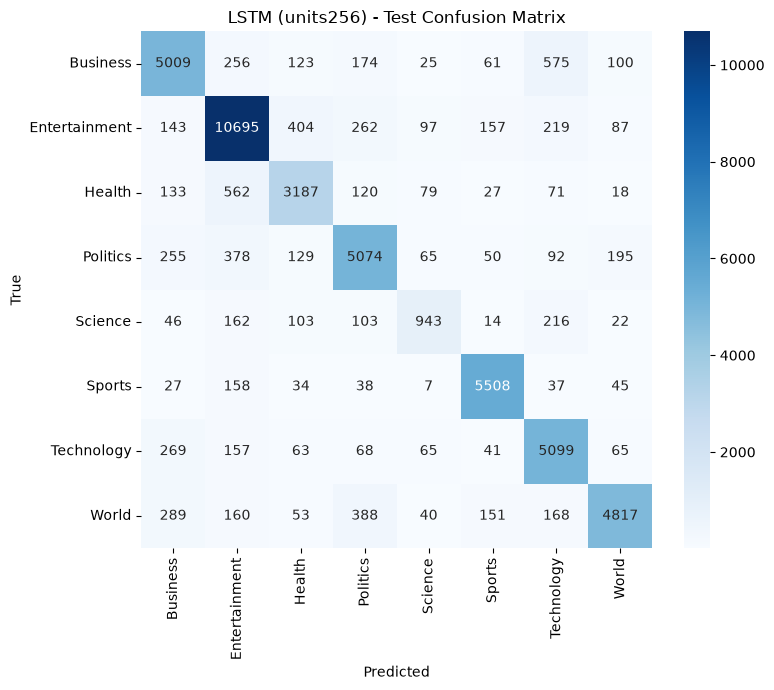

In [7]:
model = tf.keras.models.load_model(MODELS_DIR / "lstm_model.keras")

inf_start = time.time()
y_pred_probs = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
inf_time_sec = time.time() - inf_start
y_pred = np.argmax(y_pred_probs, axis=1)

report_dict = classification_report(y_test, y_pred, target_names=LABEL_ORDER, output_dict=True, zero_division=0)
print(classification_report(y_test, y_pred, target_names=LABEL_ORDER, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
test_accuracy = report_dict["accuracy"]
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Inference time: {inf_time_sec:.2f}s total, {inf_time_sec / len(test_df) * 1000:.3f} ms/sample")

plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"LSTM ({TAG}) - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "LSTM_e_confusion_matrix.png", dpi=150)
plt.show()

In [8]:
with open(MODELS_DIR / "tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

config = {
    "max_len": MAX_LEN,
    "vocab_size": VOCAB_SIZE,
    "embedding_dim": EMBEDDING_DIM,
    "lstm_units": LSTM_UNITS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "epochs_planned": EPOCHS,
    "epochs_trained": len(history.history["loss"]),
    "use_class_weights": False,
}
with open(MODELS_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=2)

metrics = {
    "model_family": "lstm",
    "model_name": "bilstm-scratch-embed",
    "variant": TAG,
    "run_timestamp": pd.Timestamp.now("UTC").isoformat(),
    "label_order": LABEL_ORDER,
    "config": config,
    "train": {
        "n_train": len(train_df),
        "n_val": len(val_df),
        "train_time_sec": train_time_sec,
        "epochs_trained": len(history.history["loss"]),
        "history": {k: [float(v) for v in vals] for k, vals in history.history.items()},
    },
    "test": {
        "n_test": len(test_df),
        "accuracy": float(test_accuracy),
        "macro_precision": float(report_dict["macro avg"]["precision"]),
        "macro_recall": float(report_dict["macro avg"]["recall"]),
        "macro_f1": float(report_dict["macro avg"]["f1-score"]),
        "weighted_f1": float(report_dict["weighted avg"]["f1-score"]),
        "per_class": {
            cls: {
                "precision": float(report_dict[cls]["precision"]),
                "recall": float(report_dict[cls]["recall"]),
                "f1": float(report_dict[cls]["f1-score"]),
                "support": int(report_dict[cls]["support"]),
            }
            for cls in LABEL_ORDER
        },
        "confusion_matrix": cm.tolist(),
        "inference_time_sec_total": inf_time_sec,
        "inference_time_ms_per_sample": inf_time_sec / len(test_df) * 1000,
    },
    "environment": {
        "framework": "tensorflow",
        "framework_version": tf.__version__,
        "device": "GPU" if tf.config.list_physical_devices("GPU") else "CPU",
        "seed": SEED,
    },
}

with open(RESULTS_DIR / "LSTM_e_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved:")
print(" ", MODELS_DIR / "lstm_model.keras")
print(" ", MODELS_DIR / "tokenizer.pkl")
print(" ", MODELS_DIR / "config.json")
print(" ", RESULTS_DIR / "LSTM_e_metrics.json")

Saved:
  ..\..\weights\lstm_variants\units256\lstm_model.keras
  ..\..\weights\lstm_variants\units256\tokenizer.pkl
  ..\..\weights\lstm_variants\units256\config.json
  ..\..\..\results\lstm\LSTM_e_metrics.json
